# Credit Card Default Prediction

**Author:** Francisco Mateus

**Dataset:** UCI *Default of Credit Card Clients* (`30,000` clients, `22.1%` default rate).

This project builds and tunes a model that predicts which clients will default on their next month's credit card payment. The tuned random forest reaches ROC AUC `0.7799` on a held-out test set, and a cost-tuned cut-off cuts the expected bank loss from `4,448` to `3,347` units per `6,000` clients.

## How this notebook is organised

1. **Setup**: imports and package versions.
2. **Dataset loading and inspection**: shape, head, columns, dtypes, data quality.
3. **Preprocessing and train/test split**: rare-code folding, encoder/scaler pipeline, stratified split, traceability.
4. **Model comparison**: majority baseline, logistic regression vs random forest (5-fold CV ROC AUC).
5. **Grid-search tuning (random forest)**: forest size and depth, training folds only.
6. **Evaluation and bank-cost view**: test metrics at the standard cut-off, then a cost-tuned cut-off from training folds.
7. **Fairness, importance and robustness**: per-group flagging rates, permutation importance, dedup probe, logistic coefficients, ROC curves.
8. **Summary**: the reproducible headline numbers.

> Every section runs in order; results are deterministic under `RANDOM_STATE = 0`.

## Setup and reproducibility

- Fixed random seed (`RANDOM_STATE = 0`) for repeatable runs.
- `requirements.txt` is generated from this environment with `pip freeze`.


### Imports and version pin


In [1]:
import sys
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from sklearn.model_selection import (
    cross_val_score,
    GridSearchCV,
    train_test_split,
    TunedThresholdClassifierCV,
)
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    make_scorer,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)

RANDOM_STATE = 0
np.random.seed(RANDOM_STATE)
pd.set_option("display.max_columns", 30)  # show all 24 columns without "..." truncation
os.makedirs("figures", exist_ok=True)  # the two figure cells write here

print(f"python {sys.version.split()[0]}")
print(f"numpy {np.__version__}")
print(f"pandas {pd.__version__}")
print(f"scikit-learn {sklearn.__version__}")
print(f"matplotlib {matplotlib.__version__}")


python 3.13.15
numpy 2.5.4
pandas 3.1.0
scikit-learn 1.9.1
matplotlib 3.11.2


## Dataset loading and inspection

- Dataset loaded locally for deterministic, offline-runnable results.
- Inspects structure and types to confirm the target column exists and no unexpected nulls or dtypes.


### Load CSV and preview


In [2]:
CSV_PATH = Path("default_of_credit_card_clients.csv")
df = pd.read_csv(CSV_PATH)

print(f"shape {df.shape}")
df.head()


shape (30000, 24)


,X1,X2,X3,X4,X5,X6,X7,X8,X9,X10,X11,X12,X13,X14,X15,X16,X17,X18,X19,X20,X21,X22,X23,default
0,20000,2,2,1,24,2,2,-1,-1,-2,-2,3913,3102,689,0,0,0,0,689,0,0,0,0,1
1,120000,2,2,2,26,-1,2,0,0,0,2,2682,1725,2682,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,90000,2,2,2,34,0,0,0,0,0,0,29239,14027,13559,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,50000,2,2,1,37,0,0,0,0,0,0,46990,48233,49291,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,50000,1,2,1,57,-1,0,-1,0,0,0,8617,5670,35835,20940,19146,19131,2000,36681,10000,9000,689,679,0


### Columns, dtypes and memory


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 24 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   X1       30000 non-null  int64
 1   X2       30000 non-null  int64
 2   X3       30000 non-null  int64
 3   X4       30000 non-null  int64
 4   X5       30000 non-null  int64
 5   X6       30000 non-null  int64
 6   X7       30000 non-null  int64
 7   X8       30000 non-null  int64
 8   X9       30000 non-null  int64
 9   X10      30000 non-null  int64
 10  X11      30000 non-null  int64
 11  X12      30000 non-null  int64
 12  X13      30000 non-null  int64
 13  X14      30000 non-null  int64
 14  X15      30000 non-null  int64
 15  X16      30000 non-null  int64
 16  X17      30000 non-null  int64
 17  X18      30000 non-null  int64
 18  X19      30000 non-null  int64
 19  X20      30000 non-null  int64
 20  X21      30000 non-null  int64
 21  X22      30000 non-null  int64
 22  X23      30000 non-null  int64
 2

### Class balance, missing values and duplicates


missing values in the whole table: 0
duplicate rows: 35
default counts {0: 23364, 1: 6636}
default rate 0.2212


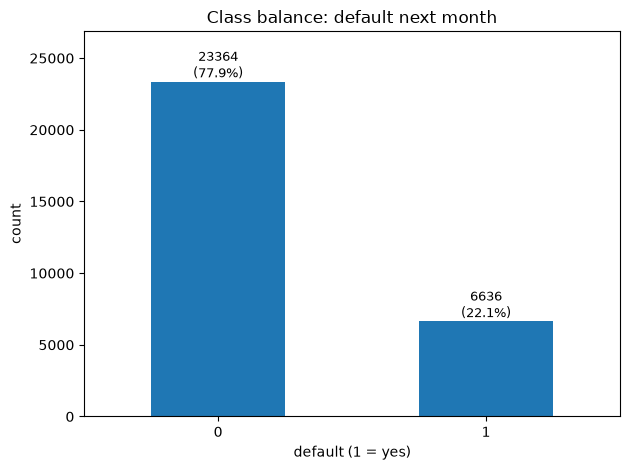

In [4]:
# target column used for preprocessing and evaluation cells
TARGET = "default"

# data-quality checks: missing values, exact duplicates, class balance 
missing = int(df.isnull().sum().sum())
dups = int(df.duplicated().sum())
counts = df[TARGET].value_counts().sort_index()
rate = float(df[TARGET].mean())

# print data-quality summary 
print(f"missing values in the whole table: {missing}")
print(f"duplicate rows: {dups}")
print(f"default counts {counts.to_dict()}")
print(f"default rate {rate:.4f}")

# plot class balance 
# make target imbalance visible
fig, ax = plt.subplots()
counts.plot(kind="bar", ax=ax, rot=0)
ax.set_title("Class balance: default next month")
ax.set_xlabel(f"{TARGET} (1 = yes)")
ax.set_ylabel("count")

# label each bar with its count and share of all rows
for i, v in enumerate(counts):
    ax.text(i, v, f"{v}\n({v / len(df):.1%})", ha="center", va="bottom", fontsize=9)

# headroom so the count labels do not overlap the title
ax.margins(y=0.15)
plt.tight_layout()
plt.savefig("figures/figure-1-class-balance.png", dpi=110, bbox_inches="tight")
plt.show()


**Data quality**

- **No missing values**: `missing values in the whole table: 0`.
- **Duplicate rows**: `35` rows are exact duplicates (label included); kept, since identical attribute patterns can belong to different clients.
- **Target imbalanced**: about `22%` default (`{0: 23364, 1: 6636}`, rate `0.2212`). A model that always predicts "no default" already scores `77.88%` accuracy, so metrics below are chosen for imbalance (ROC AUC, precision, recall, F1).


## Preprocessing and train/test split

- **Fold rare codes:** `X3` (education) has values `0,5,6` that are undocumented / rare; `X4` (marital status) has `0`. They are mapped onto the documented buckets (`X3 {0,5,6} -> 4`, `X4 {0} -> 3`) so one-hot encoding does not create near-empty, uninformative columns.
- **One-hot encode categories:** `X2` (sex), `X3` (education), `X4` (marriage) are nominal, so `OneHotEncoder` turns them into binary columns; `handle_unknown='ignore'` keeps the pipeline safe if a new category appears later.
- **Standardize numerics:** The `20` numeric columns (limit X1, age X5, repayment status X6-X11, bill amounts X12-X17, payment amounts X18-X23) are on very different scales, so `StandardScaler` puts them on a common scale, needed for logistic regression and harmless for random forests.
- **No leakage:** `ColumnTransformer` is wrapped inside a `Pipeline` and only fitted inside each CV fold / on train, so test information never leaks into preprocessing.
- **Stratified split:** `train_test_split(test_size=0.2, stratify=y, RANDOM_STATE=0)` gives `24000` train / `6000` test, and both keep the default rate `0.2212` (so evaluation reflects the real class imbalance).


### Fold rare codes, build preprocessor and stratified split


In [5]:
# categorical folding (rare codes)
df["X3"] = df["X3"].replace({0: 4, 5: 4, 6: 4})
df["X4"] = df["X4"].replace({0: 3})
print(f"X3 values after folding: {sorted(df['X3'].unique())}")
print(f"X4 values after folding: {sorted(df['X4'].unique())}")

# feature / target split
FEATURES = [c for c in df.columns if c != TARGET]
CAT_FEATURES = ["X2", "X3", "X4"]
NUM_FEATURES = [c for c in FEATURES if c not in CAT_FEATURES]
BILL_COLS = ["X12", "X13", "X14", "X15", "X16", "X17"]
X = df[FEATURES]
y = df[TARGET]

print(f"numeric features ({len(NUM_FEATURES)}): {NUM_FEATURES}")
print(f"categorical features ({len(CAT_FEATURES)}): {CAT_FEATURES}")

# preprocessor (no leakage: fit only inside CV/pipeline)
preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT_FEATURES),
        ("num", StandardScaler(), NUM_FEATURES),
    ],
    verbose_feature_names_out=False,
)

# stratified train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print(f"X_train {X_train.shape}  y_train rate {y_train.mean():.4f}")
print(f"X_test  {X_test.shape}  y_test  rate {y_test.mean():.4f}")


X3 values after folding: [np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
X4 values after folding: [np.int64(1), np.int64(2), np.int64(3)]
numeric features (20): ['X1', 'X5', 'X6', 'X7', 'X8', 'X9', 'X10', 'X11', 'X12', 'X13', 'X14', 'X15', 'X16', 'X17', 'X18', 'X19', 'X20', 'X21', 'X22', 'X23']
categorical features (3): ['X2', 'X3', 'X4']


X_train (24000, 23)  y_train rate 0.2212
X_test  (6000, 23)  y_test  rate 0.2212


### Traceability, twins and negative-bill share


In [6]:
# traceability: duplicates & credit-balance
twin_in_train = pd.merge(X_train.assign(_y=y_train.values), X_test.assign(_y=y_test.values)).shape[0]
print(f"test rows with exact twin in train: {twin_in_train} ({twin_in_train / len(X_test):.2%} of test)")

neg_bill_share = (df[BILL_COLS] < 0).any(axis=1).mean()
print(f"share with negative bill amount: {neg_bill_share:.4f}")


test rows with exact twin in train: 14 (0.23% of test)


share with negative bill amount: 0.0643


**Traceability summary**

- **Test twins**: `14` test rows have an exact twin in the training set (same attribute pattern and label), `0.23%` of the `6,000` test rows.
- **Negative bill share**: the share of clients with at least one negative bill-statement amount (credit balance, not debt) is `0.0643`.


## Model comparison (5-fold CV, ROC AUC)

- **Majority-class baseline**: Always predicting the majority class (`0`) yields accuracy `0.7788`, because most clients do not default. A useful model has to beat this trivial guess; if it cannot, it learns nothing worth having.
- **Two pipelines compared**: Logistic regression writes one weighted score per feature and turns it into a probability: simple and readable. A random forest builds many decision trees on random slices of the data and lets them vote: much more flexible, harder to read. The `preprocessor` is fitted inside each CV fold (no leakage).
- **Metric**: `roc_auc` was chosen for the imbalanced target: under imbalance, a model can look accurate while missing nearly all defaulters. ROC AUC instead asks whether the model places true defaulters higher in its ranking than non-defaulters, which works without choosing a cut-off.
- **Why 5-fold cross-validation**: A single train/validate split gets judged once; a lucky or unlucky split could decide the winner. Scoring 5 different splits and averaging averages away that luck.
- **Why training set only**: The 6000 held-out rows stay hidden until the final model exists. Tuning or comparing against them inflates the numbers that matter.


### Baselines and 5-fold CV (ROC AUC)


In [7]:
# baselines
from collections import Counter
majority_class = Counter(y_train).most_common(1)[0][0]
baseline_acc = (y_train == majority_class).mean()
print(f"majority class: {majority_class}  baseline train accuracy: {baseline_acc:.4f}")

# pipelines (preprocessing inside CV)
lr_pipe = Pipeline([("prep", clone(preprocessor)), ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))])
rf_pipe = Pipeline([("prep", clone(preprocessor)), ("clf", RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1))])

# 5-fold CV ROC AUC on training data (kept for the summary; no re-run there)
cv_auc = {}
for name, pipe in [("logistic regression", lr_pipe), ("random forest", rf_pipe)]:
    fold_scores = cross_val_score(pipe, X_train, y_train, cv=5, scoring="roc_auc")
    cv_auc[name] = fold_scores
    print(f"{name:20s} CV ROC AUC {fold_scores.mean():.4f} +/- {fold_scores.std():.4f}  (folds: {fold_scores.round(4).tolist()})")

majority class: 0  baseline train accuracy: 0.7788


logistic regression  CV ROC AUC 0.7266 +/- 0.0084  (folds: [0.7342, 0.7261, 0.7151, 0.72, 0.7374])


random forest        CV ROC AUC 0.7617 +/- 0.0078  (folds: [0.7749, 0.7515, 0.7585, 0.7649, 0.7589])


## Grid-search tuning (random forest)

- **Why only the random forest**: it won the comparison above and has settings worth trying, while the logistic regression has almost none here. Tuning runs on the **training set only** (`GridSearchCV`, 5-fold CV); the test set stays untouched (same rule as Model comparison: tuning on test inflates scores).
- **What tuning means**: A random forest has settings chosen before training (hyperparameters): how many trees the forest contains and how deep each tree may grow. The settings are not guessed; a few sensible combinations are tried and the best-scoring one is kept.
- **The grid**: `n_estimators` = number of trees in the forest (`100` or `200`); `max_depth` = how deep one tree is allowed to grow (`10` or `20` levels). That is `2 x 2 = 4` combinations, scored by ROC AUC.
- **How the winner is picked**: Each combination is judged like the comparison above: 5-fold cross-validation on the training set, ROC AUC as the score. In each fold, the model trains on 4 pieces of the training data and is checked on the 5th; the average ROC AUC across the 5 folds decides.


### GridSearchCV over forest size and depth


In [8]:
# grid-search tuning (train data only; test untouched)
rf_tune = Pipeline([
    ("prep", clone(preprocessor)),
    ("clf", RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1)),
])
param_grid = {
    "clf__n_estimators": [100, 200],
    "clf__max_depth": [10, 20],
}
grid = GridSearchCV(rf_tune, param_grid, cv=5, scoring="roc_auc")
grid.fit(X_train, y_train)
print(f"best params: {grid.best_params_}")
print(f"best CV ROC AUC: {grid.best_score_:.4f}")


results = pd.DataFrame(grid.cv_results_)[["params", "mean_test_score", "std_test_score"]]
results["mean_test_score"] = results["mean_test_score"].round(4)
results["std_test_score"] = results["std_test_score"].round(4)
print(results.sort_values("mean_test_score", ascending=False).to_string(index=False))


best params: {'clf__max_depth': 10, 'clf__n_estimators': 200}
best CV ROC AUC: 0.7795
                                          params  mean_test_score  std_test_score
{'clf__max_depth': 10, 'clf__n_estimators': 200}           0.7795          0.0071
{'clf__max_depth': 10, 'clf__n_estimators': 100}           0.7790          0.0069
{'clf__max_depth': 20, 'clf__n_estimators': 200}           0.7710          0.0062
{'clf__max_depth': 20, 'clf__n_estimators': 100}           0.7687          0.0062


## Evaluation on the test set, then a bank-cost view

- **Test-set evaluation**: the tuned forest (`200` trees, depth `10`) is fitted on the training set and scored on the `6000` held-out rows at the standard `0.5` cut-off. Metrics: accuracy, precision, recall, F1, ROC AUC, and the confusion matrix.
- **The confusion matrix named**: Four outcomes:
  - True negative: a safe client correctly cleared (no cost).
  - False positive: a safe client flagged for review (costs effort).
  - False negative: a defaulter waved through (costs the loss).
  - True positive: a defaulter caught in time.
- **What the probability means**: Each tree in the forest votes; the forest outputs the share that voted "default". A score of `0.7` means roughly 7 out of 10 trees think this client will default, `0.1` means almost none do, a confidence score, not a calibrated chance, but enough to rank clients and move the flag line without retraining.
- **Precision vs recall**: Recall asks "of everyone who actually defaulted, how many were caught?" (`482 / (845 + 482) ≈ 0.3632` at `0.5`). Precision asks "of everyone flagged, how many really defaulted?" (`482 / (223 + 482) ≈ 0.6837` at `0.5`). They pull in opposite directions: catching more defaulters raises recall but lowers precision, as more safe clients are flagged too.
- **What a cut-off is**: It turns the score into a yes/no decision. The default `0.5` says "flag at half the trees yes." Lowering it to `0.174` flags more clients: more defaulters are caught (higher recall) at the price of more false alarms (lower precision).
- **Bank-cost view**: the two error types have very different prices: each false alarm (FP) costs `1`, each missed defaulter (FN) costs `5`. A scorer that charges these prices lets the search compare cut-offs in the units the bank actually cares about. `TunedThresholdClassifierCV` searches the cut-off on **training folds only**; the test set receives only the final gain comparison.
- **Test set use**: The test set exists for reporting only; fitting, tuning and cut-off search never touch it (same train-only rule as in Model comparison).


### Tuned forest on the test set (cut-off 0.5)


In [9]:
# one-shot evaluation on the held-out test set
best_rf = grid.best_estimator_
y_pred = best_rf.predict(X_test)
y_prob = best_rf.predict_proba(X_test)[:, 1]

print(f"accuracy  {accuracy_score(y_test, y_pred):.4f}")
print(f"precision {precision_score(y_test, y_pred):.4f}")
print(f"recall    {recall_score(y_test, y_pred):.4f}")
print(f"f1        {f1_score(y_test, y_pred):.4f}")
print(f"roc auc   {roc_auc_score(y_test, y_prob):.4f}")
tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
print(f"confusion TN {tn} / FP {fp} / FN {fn} / TP {tp}")


accuracy  0.8220
precision 0.6837
recall    0.3632
f1        0.4744
roc auc   0.7799
confusion TN 4450 / FP 223 / FN 845 / TP 482


### Tune the cut-off on training folds (FP cost 1, FN cost 5)


In [10]:
# bank gain: larger is better; FP costs 1 unit, FN costs 5
def bank_gain(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return -(fp + 5 * fn)

gain_scorer = make_scorer(bank_gain)

tuned_rf = TunedThresholdClassifierCV(
    estimator=grid.best_estimator_,
    scoring=gain_scorer,
    cv=5,
)
tuned_rf.fit(X_train, y_train)
print(f"tuned cut-off: {tuned_rf.best_threshold_:.3f}")

gain_default = bank_gain(y_test, best_rf.predict(X_test))
gain_tuned = bank_gain(y_test, tuned_rf.predict(X_test))
print(f"test gain at 0.5 cut-off:  {gain_default}")
print(f"test gain at tuned cut-off: {gain_tuned}")

tp_tuned = tuned_rf.predict(X_test)
print(f"tuned-cutoff recall    {recall_score(y_test, tp_tuned):.4f}")
print(f"tuned-cutoff precision {precision_score(y_test, tp_tuned):.4f}")
print(f"tuned-cutoff f1        {f1_score(y_test, tp_tuned):.4f}")


tuned cut-off: 0.174
test gain at 0.5 cut-off:  -4448
test gain at tuned cut-off: -3347
tuned-cutoff recall    0.7159
tuned-cutoff precision 0.3939
tuned-cutoff f1        0.5082


## Fairness, importance and robustness

- **Fairness**: a cost-tuned model can look good in total and still affect one demographic more than another. At the tuned cut-off `0.174`, flagging is compared across `SEX` (from `X2`) and `EDUCATION` (from `X3`). Per group: how many people were wrongly flagged (FPR), how many defaulters were caught (TPR), and how often flagging occurred (share flagged); groups with `n < 100` are flagged as underpowered.
- **Why not one score**: `ROC AUC` averages over every cut-off, while the bank uses one (`0.174`). Per-group FPR / TPR at that single cut-off shows the price the rule actually charges to each group; one `FPR` number is not enough.
- **Importance**: on the held-out `6000` rows, one column at a time is shuffled. If the score collapses, that column mattered. The reported drop is the mean ROC AUC loss over repeats, with its spread.
- **Robustness**: if many clients are carbon copies of each other, a model trained on them may "memorize" rows. The probe retrains on the training set with its exact duplicates removed; a small drop would signal memorization. Here the drop is indeed small (`0.7799 -> 0.7796`).
- **Coefficients**: logistic regression shows direction and magnitude, fitted on the standardized/one-hot training features (test set not used for fitting).


### Fairness slices at the tuned cut-off (by SEX and EDUCATION)


In [11]:
# fairness: per-group FPR/TPR/flagged at the tuned cut-off
EDU_VALS = {1: "graduate school", 2: "university", 3: "high school", 4: "others"}
EDU_COUNTS = df["X3"].map(EDU_VALS).value_counts().to_dict()

# SEX (X2): 1=male, 2=female ; EDUCATION (X3): 1..4 after folding
y_tuned = tuned_rf.predict(X_test)

def group_stats(mask, label):
    cm = confusion_matrix(y_test[mask], y_tuned[mask], labels=[0, 1])
    tn, fp, fn, tp = cm.ravel() if cm.size == 4 else (0, 0, 0, 0)
    fpr = fp / (fp + tn) if (fp + tn) else float("nan")
    tpr = tp / (tp + fn) if (tp + fn) else float("nan")
    flagged = y_tuned[mask].mean() if len(y_tuned[mask]) else float("nan")
    return {label: {"n": int(mask.sum()), "FPR": fpr, "TPR": tpr, "flagged": flagged}}

agg = {}
for val, name in [(1, "male"), (2, "female")]:
    mask = (X_test["X2"] == val).to_numpy()
    agg.update(group_stats(mask, name))
for val in [1, 2, 3, 4]:
    mask = (X_test["X3"] == val).to_numpy()
    agg.update(group_stats(mask, EDU_VALS[val]))
out = pd.DataFrame.from_dict(agg, orient="index")
out.index.name = "group"
# underpowered = the group's own test-set size, not its share of the whole frame
out["note"] = out["n"].map(lambda n: "n<100 -- underpowered" if n < 100 else "")

print("education counts overall (from X3):", EDU_COUNTS)
print(out.round(4).to_string())

education counts overall (from X3): {'university': 14030, 'graduate school': 10585, 'high school': 4917, 'others': 468}
                    n     FPR     TPR  flagged                   note
group                                                                
male             2436  0.3389  0.7216   0.4314                       
female           3564  0.2958  0.7114   0.3819                       
graduate school  2109  0.2860  0.6998   0.3651                       
university       2825  0.3217  0.6997   0.4081                       
high school       975  0.3626  0.7918   0.4810                       
others             91  0.2073  0.3333   0.2198  n<100 -- underpowered


### Permutation importance on the test set


In [12]:
# permutation importance (ROC AUC loss on test set)
perm = permutation_importance(
    grid.best_estimator_,
    X_test, y_test,
    n_repeats=10,
    scoring="roc_auc",
    random_state=RANDOM_STATE,
)
perm_df = pd.DataFrame({
    "feature": FEATURES,
    "importance": perm.importances_mean,
    "std": perm.importances_std,
})
perm_df = perm_df.sort_values("importance", ascending=False)

print(perm_df.round(4).head(10).to_string(index=False))
print(f"top feature: {perm_df.iloc[0]['feature']} importance +{perm_df.iloc[0]['importance']:.4f} +/- {perm_df.iloc[0]['std']:.4f}")


feature  importance    std
     X6      0.0694 0.0031
     X7      0.0177 0.0027
     X1      0.0120 0.0020
    X18      0.0092 0.0023
     X8      0.0079 0.0015
    X12      0.0067 0.0009
     X9      0.0065 0.0020
    X11      0.0036 0.0014
    X13      0.0034 0.0008
    X10      0.0030 0.0016
top feature: X6 importance +0.0694 +/- 0.0031


### Robustness: duplicate drop


In [13]:
# dedup robustness: retrain on the training set without its exact duplicates
# Apples-to-apples: only the training rows change; the test set, the split and the tuned forest stay the same, 
#   so the AUC difference isolates the effect of duplicate rows on training
dedup_train = X_train.copy()
dedup_train[TARGET] = y_train.values
before = len(dedup_train)
dedup_train = dedup_train.drop_duplicates()
removed = before - len(dedup_train)
print(f"train rows after dedup: {len(dedup_train)} (removed {removed} of the frame's {dups} exact duplicates)")

Xtr_d, ytr_d = dedup_train[FEATURES], dedup_train[TARGET]
dedup_pipe = clone(grid.best_estimator_).fit(Xtr_d, ytr_d)
prob_d = dedup_pipe.predict_proba(X_test)[:, 1]
print(f"plain  train -> test ROC AUC {roc_auc_score(y_test, y_prob):.4f}")
print(f"dedup  train -> test ROC AUC {roc_auc_score(y_test, prob_d):.4f}")

train rows after dedup: 23979 (removed 21 of the frame's 35 exact duplicates)


plain  train -> test ROC AUC 0.7799
dedup  train -> test ROC AUC 0.7796


### What the logistic model leans on (for context)


In [14]:
# logistic coefficients: direction and magnitude
lr_pipe.fit(X_train, y_train)
coef_names = lr_pipe.named_steps["prep"].get_feature_names_out()
coefs = lr_pipe.named_steps["clf"].coef_[0]
coef_df = pd.DataFrame({"feature": coef_names, "coef": coefs})
coef_df["abs"] = coef_df["coef"].abs()

print(coef_df.sort_values("abs", ascending=False).round(4).head(12).to_string(index=False))


feature    coef    abs
   X3_4 -1.0377 1.0377
     X6  0.6401 0.6401
    X12 -0.4728 0.4728
   X2_2 -0.4628 0.4628
   X2_1 -0.3605 0.3605
   X4_2 -0.3375 0.3375
   X4_3 -0.3194 0.3194
    X18 -0.2826 0.2826
    X13  0.2462 0.2462
    X19 -0.1679 0.1679
   X4_1 -0.1665 0.1665
   X3_1  0.1505 0.1505


### ROC curves (all three models)


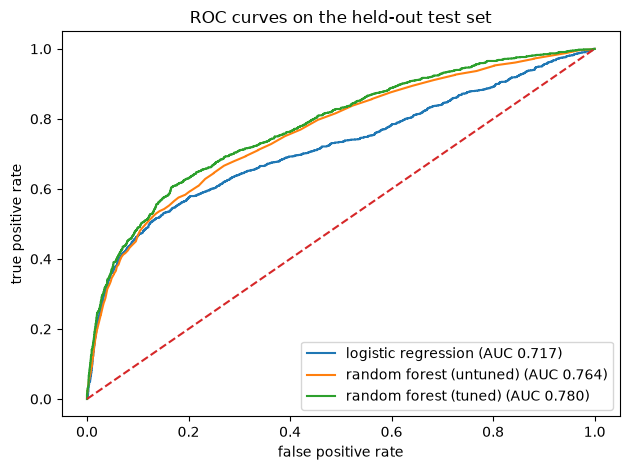

In [15]:
# draw ROC curves once: LR, untuned RF, tuned RF
# LR was fitted on the training set in the coefficients cell; the untuned RF is fitted here (training set only); 
# Tuned RF is the fitted grid winner
rf_plain = clone(rf_pipe).fit(X_train, y_train)
probs = {
    "logistic regression": lr_pipe.predict_proba(X_test)[:, 1],
    "random forest (untuned)": rf_plain.predict_proba(X_test)[:, 1],
    "random forest (tuned)": best_rf.predict_proba(X_test)[:, 1],
    
}
fig, ax = plt.subplots()
for name, prob in probs.items():
    fpr, tpr, _ = roc_curve(y_test, prob)
    ax.plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(y_test, prob):.3f})")
ax.plot([0, 1], [0, 1], linestyle="--")
ax.set_xlabel("false positive rate")
ax.set_ylabel("true positive rate")
ax.set_title("ROC curves on the held-out test set")
ax.legend()

plt.tight_layout()
plt.savefig("figures/figure-2-roc-curves.png", dpi=110, bbox_inches="tight")
plt.show()


## Summary

> **Deterministic results**: every split, fold and forest uses `RANDOM_STATE = 0`; re-running the notebook reproduces the headline numbers below.


### Reproducible headline numbers


In [16]:
# summary: headline numbers from this run (no hardcoding)
print("Data:     ", f"dataset {df.shape}, missing {missing}, dups {dups}, rate {rate:.4f}")
print("Split:    ", f"train {X_train.shape} / test {X_test.shape}, twins {twin_in_train} ({twin_in_train / len(X_test):.2%}), neg-bill {neg_bill_share:.4f}")
print("Models:   ", f"baseline {baseline_acc:.4f}, LR CV {cv_auc['logistic regression'].mean():.4f}, RF100 CV {cv_auc['random forest'].mean():.4f}")
print("Tuning:   ", f"best {grid.best_params_}, CV {grid.best_score_:.4f}")

tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
print("Test@0.5: ", f"acc {accuracy_score(y_test, y_pred):.4f}, prec {precision_score(y_test, y_pred):.4f}, rec {recall_score(y_test, y_pred):.4f}, f1 {f1_score(y_test, y_pred):.4f}, auc {roc_auc_score(y_test, y_prob):.4f}, TN{tn} FP{fp} FN{fn} TP{tp}")
print("Tuned:    ", f"cut-off {tuned_rf.best_threshold_:.3f}, gain {bank_gain(y_test, y_pred):.0f} -> {bank_gain(y_test, tuned_rf.predict(X_test)):.0f}")
print("Importance:", f"top {perm_df.iloc[0]['feature']} {perm_df.iloc[0]['importance']:.4f} +/- {perm_df.iloc[0]['std']:.4f}, dedup AUC {roc_auc_score(y_test, prob_d):.4f}")

male, female, high_school = out.loc["male"], out.loc["female"], out.loc["high school"]
print("Fairness: ", f"male FPR {male['FPR']:.4f} flagged {male['flagged']:.4f}, female FPR {female['FPR']:.4f} flagged {female['flagged']:.4f}, high-school flagged {high_school['flagged']:.4f}")


Data:      dataset (30000, 24), missing 0, dups 35, rate 0.2212
Split:     train (24000, 23) / test (6000, 23), twins 14 (0.23%), neg-bill 0.0643
Models:    baseline 0.7788, LR CV 0.7266, RF100 CV 0.7617
Tuning:    best {'clf__max_depth': 10, 'clf__n_estimators': 200}, CV 0.7795
Test@0.5:  acc 0.8220, prec 0.6837, rec 0.3632, f1 0.4744, auc 0.7799, TN4450 FP223 FN845 TP482
Tuned:     cut-off 0.174, gain -4448 -> -3347
Importance: top X6 0.0694 +/- 0.0031, dedup AUC 0.7796
Fairness:  male FPR 0.3389 flagged 0.4314, female FPR 0.2958 flagged 0.3819, high-school flagged 0.4810
